# Лабораторная работа 4.1

Методы Эйлера, Рунге-Кутты и Адамса 4-го порядка для задачи Коши ОДУ 2-го порядка.

Вариант 11:

$$y'' + y'\tan x - y\cos^2 x = 0,$$
$$y(0)=2,\quad y'(0)=0,\quad x\in[0,1],\quad h=0.1.$$

Точное решение:
$$y=e^{\sin x}+e^{-\sin x}.$$

In [1]:
import numpy as np

from nm.ode import (
    adams_bashforth_method,
    euler_method,
    exact_solution_error,
    reduce_second_order_ode,
    runge_kutta_method,
    runge_romberg_errors,
)

In [2]:
def right_side(x, y, derivative):
    return y * np.cos(x) ** 2 - derivative * np.tan(x)


def exact_solution(x):
    return np.exp(np.sin(x)) + np.exp(-np.sin(x))


system = reduce_second_order_ode(right_side)
initial_state = [2.0, 0.0]
left, right, step = 0.0, 1.0, 0.1

In [3]:
def print_table(title, x, values, rr_errors, exact_errors):
    print(title)
    print('x       y           y\'          RR error    exact error')
    for i, xi in enumerate(x):
        print(
            f'{xi:0.1f}  {values[i, 0]: .10f}  {values[i, 1]: .10f}  '
            f'{rr_errors[i]: .10f}  {exact_errors[i]: .10f}'
        )


methods = [
    ('Метод Эйлера', euler_method, 1),
    ('Метод Рунге-Кутты 4-го порядка', runge_kutta_method, 4),
    ('Метод Адамса 4-го порядка', adams_bashforth_method, 4),
]

for title, method, order in methods:
    x, values = method(system, left, right, step, initial_state)
    _, fine_values = method(system, left, right, step / 2, initial_state)
    rr_errors = runge_romberg_errors(values[:, 0], fine_values[:, 0], step, step / 2, order)
    exact_errors = exact_solution_error(exact_solution, x, values)
    print_table(title, x, values, rr_errors, exact_errors)
    print()

Метод Эйлера
x       y           y'          RR error    exact error
0.0   2.0000000000   0.0000000000   0.0000000000   0.0000000000
0.1   2.0000000000   0.2000000000   0.0050000000   0.0099749918
0.2   2.0200000000   0.3959999643   0.0098624999   0.0195994941
0.3   2.0595999964   0.5819998081   0.0143370794   0.0283696252
0.4   2.1177999772   0.7519695056   0.0181699926   0.0357727736
0.5   2.1929969278   0.8998410163   0.0211027076   0.0412883297
0.6   2.2829810294   1.0195763888   0.0228762229   0.0444012033
0.7   2.3849386683   1.1053352606   0.0232429994   0.0446310190
0.8   2.4954721944   1.1517491499   0.0219872039   0.0415773432
0.9   2.6106471094   1.1542908965   0.0189525400   0.0349782733
1.0   2.7260761990   1.1097071116   0.0140753824   0.0247765764

Метод Рунге-Кутты 4-го порядка
x       y           y'          RR error    exact error
0.0   2.0000000000   0.0000000000   0.0000000000   0.0000000000
0.1   2.0099750209   0.1989987593   0.0000000019   0.0000000291
0.2   2.039

Наименьшую погрешность на данном шаге показывает метод Рунге-Кутты 4-го порядка. Метод Адамса также имеет 4-й порядок, но первые значения он получает стартовым методом Рунге-Кутты, а дальнейшие значения вычисляет по явной многошаговой формуле.

# Лабораторная работа 4.2

Метод стрельбы и конечно-разностный метод для краевой задачи ОДУ 2-го порядка.

Вариант 11:

$$x(x-1)y''-xy'+y=0,\quad x\in[1,2],$$
$$y'(1)=2,\quad 2y'(2)-y(2)=1.$$

Точное решение:
$$y(x)=1+x+x\ln x.$$

В точке $x=1$ коэффициент при $y''$ обращается в ноль. Поэтому для метода стрельбы интегрируем справа налево от условия $2y'(2)-y(2)=1$, подбирая $\eta=y(2)$. Для конечно-разностного метода из исходного уравнения при $x=1$ следует $-y'(1)+y(1)=0$, а значит при $y'(1)=2$ имеем $y(1)=2$.


In [4]:
import matplotlib.pyplot as plt

from nm.ode import (
    BoundaryCondition,
    finite_difference_method,
    runge_romberg_grid_errors,
    shooting_method,
)

In [5]:
def bvp_exact_solution(x):
    return 1 + x + x * np.log(x)


def bvp_right_side(x, y, derivative):
    if np.isclose(x, 1.0):
        return 1.0
    return (x * derivative - y) / (x * (x - 1))


def bvp_a(x):
    return x * (x - 1)


def bvp_b(x):
    return -x


def bvp_c(x):
    return 1.0


def bvp_f(x):
    return 0.0


left, right, step = 1.0, 2.0, 0.1
shooting_left_boundary = BoundaryCondition(alpha=0.0, beta=1.0, value=2.0)
right_boundary = BoundaryCondition(alpha=-1.0, beta=2.0, value=1.0)
difference_left_boundary = BoundaryCondition(alpha=1.0, beta=0.0, value=2.0)


In [6]:
def print_bvp_table(title, x, y, fine_y, rr_errors):
    exact_values = bvp_exact_solution(x)
    coarse_exact_errors = np.abs(y - exact_values)
    fine_exact_errors = np.abs(fine_y[::2] - exact_values)
    print(title)
    print('x     y              exact          RR error       exact error h   exact error h/2')
    for xi, yi, exact_i, rr_i, coarse_error_i, fine_error_i in zip(
        x,
        y,
        exact_values,
        rr_errors,
        coarse_exact_errors,
        fine_exact_errors,
    ):
        print(
            f'{xi:0.1f}  {yi: .10f}  {exact_i: .10f}  {rr_i: .10f}  '
            f'{coarse_error_i: .10f}  {fine_error_i: .10f}'
        )


In [7]:
x_shooting, shooting_values, eta, phi = shooting_method(
    bvp_right_side,
    left=left,
    right=right,
    step=step,
    left_boundary=shooting_left_boundary,
    right_boundary=right_boundary,
    eta0=4.0,
    eta1=5.0,
    shoot_from='right',
)
_, shooting_fine_values, _, _ = shooting_method(
    bvp_right_side,
    left=left,
    right=right,
    step=step / 2,
    left_boundary=shooting_left_boundary,
    right_boundary=right_boundary,
    eta0=4.0,
    eta1=5.0,
    shoot_from='right',
)

shooting_rr_errors = runge_romberg_grid_errors(
    shooting_values[:, 0],
    shooting_fine_values[:, 0],
    step,
    step / 2,
    order=4,
)

print(f'Найденное eta = y(2) = {eta:.10f}')
print(f'Ф(eta) = {phi(eta):.3e}')
print_bvp_table(
    'Метод стрельбы',
    x_shooting,
    shooting_values[:, 0],
    shooting_fine_values[:, 0],
    shooting_rr_errors,
)


Найденное eta = y(2) = 4.3834621803
Ф(eta) = 4.441e-16
Метод стрельбы
x     y              exact          RR error       exact error h   exact error h/2
1.0   1.9985109838   2.0000000000   0.0000733118   0.0014890162   0.0003893391
1.1   2.2032756440   2.2048411978   0.0000765029   0.0015655538   0.0004180101
1.2   2.4170836144   2.4187858682   0.0000831050   0.0017022537   0.0004556790
1.3   2.6392310874   2.6410735438   0.0000899266   0.0018424564   0.0004935567
1.4   2.8690776812   2.8710611313   0.0000967980   0.0019834501   0.0005314796
1.5   3.1060729359   3.1081976622   0.0001036872   0.0021247263   0.0005694187
1.6   3.3497396769   3.3520058068   0.0001105843   0.0022661299   0.0006073653
1.7   3.5996604273   3.6020680268   0.0001174856   0.0024075995   0.0006453157
1.8   3.8554668901   3.8580159968   0.0001243892   0.0025491067   0.0006832683
1.9   4.1168317472   4.1195223837   0.0001312943   0.0026906366   0.0007212224
2.0   4.3834621803   4.3862943611   0.0001382002   0.0028

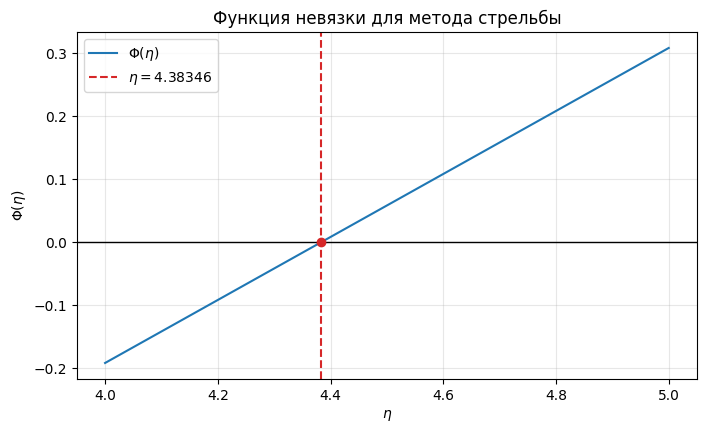

In [8]:
eta_values = np.linspace(4.0, 5.0, 101)
phi_values = np.array([phi(eta_i) for eta_i in eta_values])

plt.figure(figsize=(8, 4.5))
plt.plot(eta_values, phi_values, label=r'$\Phi(\eta)$')
plt.axhline(0.0, color='black', linewidth=1)
plt.axvline(eta, color='tab:red', linestyle='--', label=fr'$\eta={eta:.5f}$')
plt.scatter([eta], [phi(eta)], color='tab:red', zorder=3)
plt.xlabel(r'$\eta$')
plt.ylabel(r'$\Phi(\eta)$')
plt.title('Функция невязки для метода стрельбы')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [9]:
x_difference, difference_values = finite_difference_method(
    bvp_b,
    bvp_c,
    bvp_f,
    left=left,
    right=right,
    step=step,
    left_boundary=difference_left_boundary,
    right_boundary=right_boundary,
    a=bvp_a,
)
_, difference_fine_values = finite_difference_method(
    bvp_b,
    bvp_c,
    bvp_f,
    left=left,
    right=right,
    step=step / 2,
    left_boundary=difference_left_boundary,
    right_boundary=right_boundary,
    a=bvp_a,
)

difference_rr_errors = runge_romberg_grid_errors(
    difference_values,
    difference_fine_values,
    step,
    step / 2,
    order=2,
)

print_bvp_table(
    'Конечно-разностный метод',
    x_difference,
    difference_values,
    difference_fine_values,
    difference_rr_errors,
)


Конечно-разностный метод
x     y              exact          RR error       exact error h   exact error h/2
1.0   2.0000000000   2.0000000000   0.0000000000   0.0000000000   0.0000000000
1.1   2.2049868766   2.2048411978   0.0000363504   0.0001456789   0.0000366278
1.2   2.4190408017   2.4187858682   0.0000635535   0.0002549336   0.0000642732
1.3   2.6414061879   2.6410735438   0.0000828314   0.0003326441   0.0000841498
1.4   2.8714436919   2.8710611313   0.0000951239   0.0003825606   0.0000971890
1.5   3.1086053055   3.1081976622   0.0001011730   0.0004076433   0.0001041243
1.6   3.3524160878   3.3520058068   0.0001015780   0.0004102811   0.0001055472
1.7   3.6024604660   3.6020680268   0.0000968319   0.0003924392   0.0001019437
1.8   3.8583717579   3.8580159968   0.0000873472   0.0003557611   0.0000937196
1.9   4.1198240239   4.1195223837   0.0000734738   0.0003016401   0.0000812189
2.0   4.3865256336   4.3862943611   0.0000555120   0.0002312725   0.0000647364


Оценка Рунге-Ромберга считалась по решениям на шагах $h$ и $h/2$. Для конечно-разностного метода использован порядок 2.

Для метода стрельбы внутри используется Рунге-Кутта 4-го порядка, однако в этой задаче левая крайняя точка вырожденная: $x(x-1)=0$ при $x=1$. После приведения уравнения к виду $y''=f(x,y,y')$ появляется деление на $x(x-1)$, поэтому около левой границы правая часть плохо обусловлена. Из-за этого полная процедура стрельбы на этой краевой задаче показывает наблюдаемый порядок ближе к $h^2$, а не к $h^4$. Поэтому оценка Рунге-Ромберга с порядком 4 получается слишком оптимистичной.
